# Tahap 2 sampai 4: Eksplorasi, Praproses, Validasi, dan Baseline
**Proyek:** Peramalan PM2.5 Beijing (Muhammad Alif Qadri, D082261018)

Tujuan bagian ini sederhana: **mengenal data, menyiapkannya, dan menetapkan acuan (*baseline*)** sebelum model lanjutan dibuat.

Aturan yang dipegang sepanjang *notebook*:
1. Data uji (20% periode terakhir) disisihkan **di awal** dan tidak dilihat.
2. Model meramal PM2.5 **24 jam ke depan**, jadi fitur hanya boleh memakai data sampai jam sekarang.
3. Tidak ada langkah yang memakai nilai dari masa depan (misalnya interpolasi).
4. Validasi berurutan waktu memakai jarak aman 24 jam antara data latih dan data validasi.

Nomor bagian mengikuti struktur *notebook* dari dosen:

| No | Isi |
|---|---|
| 00 | Pengaturan |
| 01 | Rumusan masalah (ringkas) |
| 02 | Muat data, sisihkan data uji, lalu eksplorasi (EDA) |
| 03 | Pembagian data dan skema validasi |
| 04 | Fitur, *pipeline* praproses, dan *baseline* |

Keputusan proyek yang dipakai (dari penulis, bukan aturan dosen):
* Horizon 24 jam, stasiun utama Tiantan, nilai ekstrem dipertahankan (14 Nov 2026).
* Tanpa *forward fill* (15 Nov 2026). Pengisian 0 sampai 24 jam dibandingkan pada validasi data latih Tiantan dan tidak ada beda yang bisa dibedakan dari derau, jadi dipilih yang paling sederhana.
* Stasiun uji: Dingling (15 Nov 2026), karena distribusi PM2.5-nya paling berbeda dari Tiantan pada data latih. Belum dipakai, dibuka satu kali di tahap 7.

Catatan urutan: data uji disisihkan **di awal bagian 02**, sebelum eksplorasi, sesuai Kode 1 panduan
("data uji disisihkan sekarang, sebelum eksplorasi lebih jauh"). Bagian 03 merinci aturan pembagiannya.

## 00. Pengaturan

In [1]:
# Sumber data:
# 1) Google Drive pemilik (folder "Dataset PM25 Beijing"), jika ada.
# 2) Folder Data/Data Mentah di repo ini (dijalankan dari akar repo atau dari folder Notebook).
# 3) Jika keduanya tidak ada (misalnya dijalankan dosen), repo GitHub publik diunduh.
import os, subprocess
REPO = "https://github.com/LippyyDev/Tugas-Machine-Learning-PM25-Beijing"

FOLDER = os.environ.get("FOLDER_DATA")
if FOLDER is None:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        calon = "/content/drive/MyDrive/Dataset PM25 Beijing"
        FOLDER = calon if os.path.isdir(calon) else None
    except Exception:
        pass
if FOLDER is None:
    for calon in ("Data/Data Mentah", "../Data/Data Mentah"):
        if os.path.isdir(calon):
            FOLDER = calon                                # dijalankan dari dalam repo
            break
    else:
        if not os.path.isdir("repo_pm25"):
            subprocess.run(["git", "clone", "--depth", "1", REPO, "repo_pm25"], check=True)
        FOLDER = "repo_pm25/Data/Data Mentah"

# Keluaran meniru struktur repo: Hasil/Gambar, Hasil/Tabel, Data/Data Olahan.
# Di repo, akar = folder yang memuat "Data". Di Drive, akar = folder data itu sendiri.
if os.path.basename(os.path.normpath(FOLDER)) == "Data Mentah":
    AKAR = os.path.abspath(os.path.join(FOLDER, "..", ".."))
else:
    AKAR = os.path.abspath(FOLDER)
GAMBAR = os.path.join(AKAR, "Hasil", "Gambar")
TABEL = os.path.join(AKAR, "Hasil", "Tabel")
OLAHAN = os.path.join(AKAR, "Data", "Data Olahan")
for d in (GAMBAR, TABEL, OLAHAN):
    os.makedirs(d, exist_ok=True)
print("Folder data   :", FOLDER)
print("Keluaran disimpan di Hasil/Gambar, Hasil/Tabel, dan Data/Data Olahan di bawah folder:",
      os.path.basename(AKAR))

Folder data   : ../Data/Data Mentah
Keluaran disimpan di Hasil/Gambar, Hasil/Tabel, dan Data/Data Olahan di bawah folder: tugas-machine-learning-pm25-beijing


In [2]:
import glob, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

SEED = 42
np.random.seed(SEED)

# Warna grafik: biru = data utama, oranye = sorotan, abu-abu = pembanding
BIRU, ORANYE, ABU = "#2a78d6", "#eb6834", "#b4b2a9"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

def simpan_gambar(nama):
    plt.tight_layout()
    plt.savefig(os.path.join(GAMBAR, nama), dpi=150)
    plt.show()

print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 01. Rumusan masalah (ringkas)
* **Target:** konsentrasi PM2.5 pada **24 jam ke depan** di stasiun Tiantan.
* **Fitur:** hanya data yang sudah tersedia saat ramalan dibuat (polutan, cuaca, waktu).
* **Metrik utama:** RMSE, karena galat besar saat polusi tinggi paling merugikan. MAE sebagai pendamping.

Rumusan lengkap ada di proposal.

## 02. Muat data dan eksplorasi
### 02.1 Muat data
Ada 12 berkas CSV, satu per stasiun. Semuanya digabung menjadi satu tabel.

In [3]:
berkas = sorted(glob.glob(os.path.join(FOLDER, "*.csv")))
df = pd.concat([pd.read_csv(f) for f in berkas], ignore_index=True)
df["waktu"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values(["station", "waktu"]).reset_index(drop=True)

print(f"{len(berkas)} berkas, {df.shape[0]:,} baris, {df.shape[1]} kolom")
print("Rentang waktu:", df["waktu"].min(), "sampai", df["waktu"].max())
df.head(3)

12 berkas, 420,768 baris, 19 kolom
Rentang waktu: 2013-03-01 00:00:00 sampai 2017-02-28 23:00:00


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,waktu
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00


### 02.2 Sisihkan data uji (sebelum eksplorasi)
Data uji adalah **20% periode terakhir**, dipotong menurut waktu tanpa diacak.
Batas waktunya sama untuk semua stasiun, supaya uji di stasiun lain memakai periode yang sama.

Mulai di sini, semua eksplorasi **hanya memakai data latih**.

In [4]:
jam_unik = np.sort(df["waktu"].unique())
BATAS = pd.Timestamp(jam_unik[int(len(jam_unik) * 0.8)])   # jam pertama periode uji

latih = df[df["waktu"] < BATAS].copy()
print("Batas data uji :", BATAS)
print(f"Baris latih    : {len(latih):,} ({len(latih)/len(df):.0%})")
print(f"Baris uji      : {(df['waktu'] >= BATAS).sum():,} (disisihkan, tidak dilihat)")

Batas data uji : 2016-05-12 19:00:00
Baris latih    : 336,612 (80%)
Baris uji      : 84,156 (disisihkan, tidak dilihat)


### 02.3 Statistik deskriptif (stasiun utama: Tiantan)

In [5]:
STASIUN = "Tiantan"
STASIUN_UJI = "Dingling"      # keputusan 15 Nov 2026; baru dipakai di tahap 7, belum dibuka
tt = latih[latih["station"] == STASIUN].set_index("waktu")
tt[["PM2.5", "PM10", "TEMP", "DEWP", "PRES", "WSPM", "RAIN"]].describe().round(1)

,PM2.5,PM10,TEMP,DEWP,PRES,WSPM,RAIN
count,27467.0,27534.0,28049.0,28049.0,28049.0,28049.0,28049.0
mean,82.2,107.2,13.5,2.0,1012.4,1.9,0.1
std,79.9,87.8,11.2,13.7,10.1,1.3,0.7
min,3.0,2.0,-16.8,-35.3,987.1,0.0,0.0
25%,22.0,41.0,3.4,-9.2,1004.2,1.0,0.0
50%,59.0,88.0,14.5,2.1,1012.1,1.5,0.0
75%,114.0,146.0,23.0,14.5,1020.5,2.5,0.0
max,821.0,988.0,41.1,28.8,1042.0,10.5,36.6


### 02.4 Sebaran PM2.5
Seberapa sering udara bersih, dan seberapa sering sangat kotor?

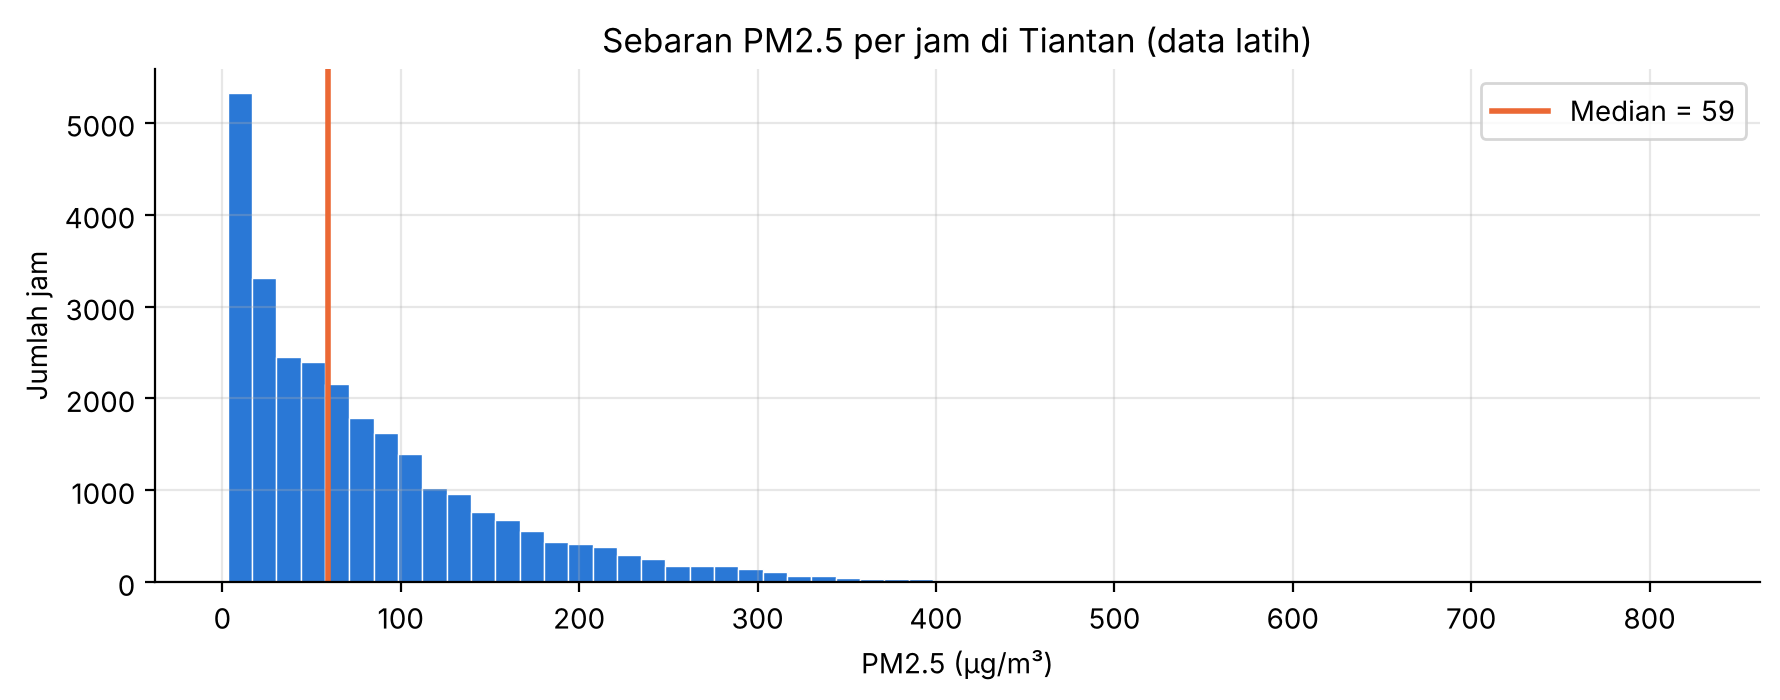

Rata-rata 82.2 | median 59.0 | kemiringan (skewness) 1.91


In [6]:
pm = tt["PM2.5"].dropna()
fig, ax = plt.subplots()
ax.hist(pm, bins=60, color=BIRU, edgecolor="white", linewidth=0.5)
ax.axvline(pm.median(), color=ORANYE, lw=2, label=f"Median = {pm.median():.0f}")
ax.set(title=f"Sebaran PM2.5 per jam di {STASIUN} (data latih)",
       xlabel="PM2.5 (µg/m³)", ylabel="Jumlah jam")
ax.legend()
simpan_gambar("t2_01_sebaran_pm25.png")

print(f"Rata-rata {pm.mean():.1f} | median {pm.median():.1f} | "
      f"kemiringan (skewness) {pm.skew():.2f}")

### 02.5 Nilai ekstrem
Nilai sangat tinggi bisa berarti episode polusi nyata atau galat sensor.
Kita cek di seluruh stasiun (data latih), lalu lihat apakah nilai itu muncul sendirian atau bersamaan di banyak stasiun.

In [7]:
pm_semua = latih["PM2.5"]
print("Jumlah jam dengan PM2.5:")
for ambang in [500, 700, 900]:
    print(f"  di atas {ambang}: {(pm_semua > ambang).sum():>4}")
print("  tepat 999   :", (pm_semua == 999).sum())

# Apakah nilai > 700 terjadi serempak? Hitung berapa stasiun yang juga > 300 pada jam itu.
jam_ekstrem = latih.loc[latih["PM2.5"] > 700, "waktu"].unique()
serempak = (latih[latih["waktu"].isin(jam_ekstrem)]
            .groupby("waktu")["PM2.5"].apply(lambda s: (s > 300).sum()))
print(f"\nPada {len(jam_ekstrem)} jam dengan PM2.5 > 700 di suatu stasiun, "
      f"median jumlah stasiun lain yang juga > 300: {serempak.median():.0f} dari 12")

Jumlah jam dengan PM2.5:
  di atas 500:  659
  di atas 700:   32
  di atas 900:    3
  tepat 999   : 1

Pada 19 jam dengan PM2.5 > 700 di suatu stasiun, median jumlah stasiun lain yang juga > 300: 10 dari 12


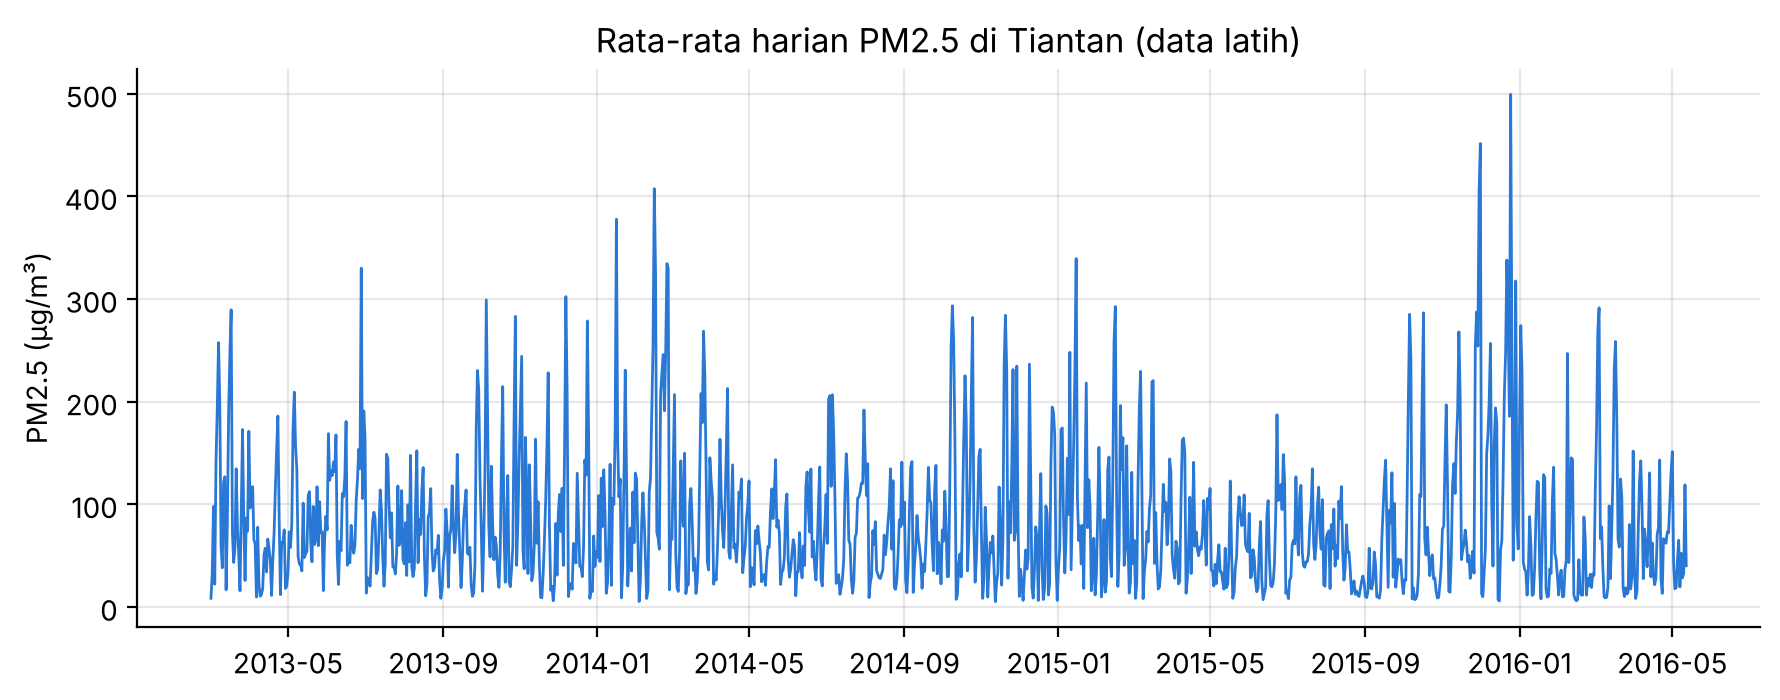

In [8]:
# Deret waktu Tiantan: terlihat kapan episode polusi tinggi terjadi
fig, ax = plt.subplots()
harian = tt["PM2.5"].resample("D").mean()
ax.plot(harian.index, harian, color=BIRU, lw=1)
ax.set(title=f"Rata-rata harian PM2.5 di {STASIUN} (data latih)",
       ylabel="PM2.5 (µg/m³)")
simpan_gambar("t2_02_deret_waktu_harian.png")

### 02.6 Pola harian dan musiman
Kapan polusi paling tinggi? Pola ini menjadi dasar fitur kalender (jam dan bulan).

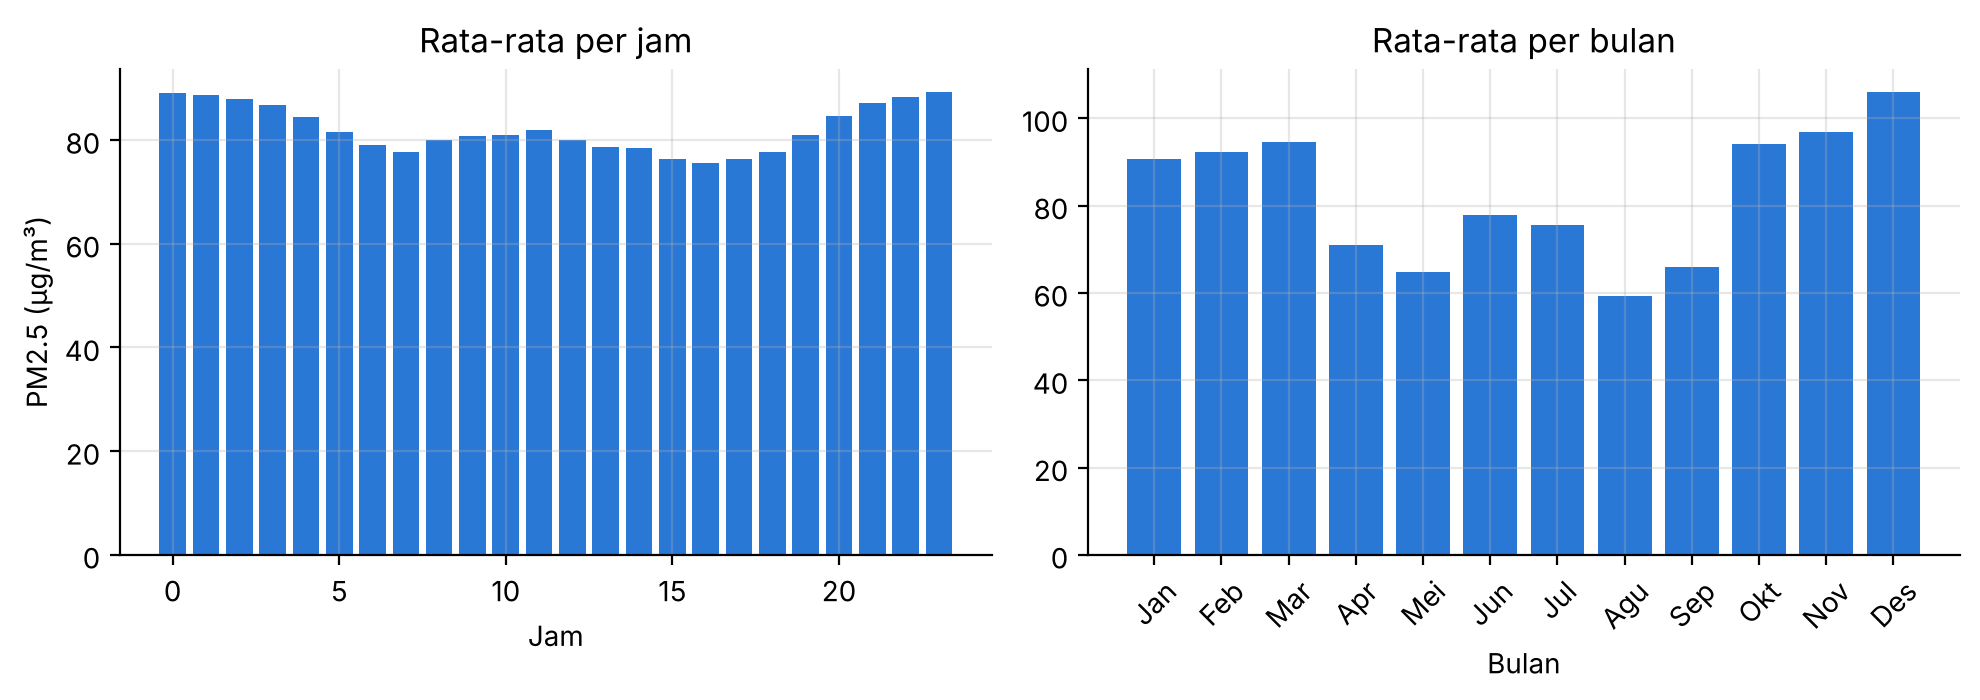

Jam tertinggi: 23:00 (89) | terendah: 16:00 (76)
Bulan tertinggi: Des (106) | terendah: Agu (59)


In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
per_jam = tt.groupby(tt.index.hour)["PM2.5"].mean()
a1.bar(per_jam.index, per_jam, color=BIRU, width=0.8)
a1.set(title="Rata-rata per jam", xlabel="Jam", ylabel="PM2.5 (µg/m³)")

nama_bulan = ["Jan","Feb","Mar","Apr","Mei","Jun","Jul","Agu","Sep","Okt","Nov","Des"]
per_bulan = tt.groupby(tt.index.month)["PM2.5"].mean()
a2.bar([nama_bulan[m-1] for m in per_bulan.index], per_bulan, color=BIRU, width=0.8)
a2.set(title="Rata-rata per bulan", xlabel="Bulan")
a2.tick_params(axis="x", rotation=45)
simpan_gambar("t2_03_pola_jam_bulan.png")

print(f"Jam tertinggi: {per_jam.idxmax()}:00 ({per_jam.max():.0f}) | "
      f"terendah: {per_jam.idxmin()}:00 ({per_jam.min():.0f})")
print(f"Bulan tertinggi: {nama_bulan[per_bulan.idxmax()-1]} ({per_bulan.max():.0f}) | "
      f"terendah: {nama_bulan[per_bulan.idxmin()-1]} ({per_bulan.min():.0f})")

### 02.7 Data bolong (nilai hilang)
Dua hal yang dicek: **berapa banyak** yang hilang, dan **berapa lama** celahnya.
Panjang celah menentukan seberapa berbahaya tebakan pengisiannya (dibahas di 04.1).

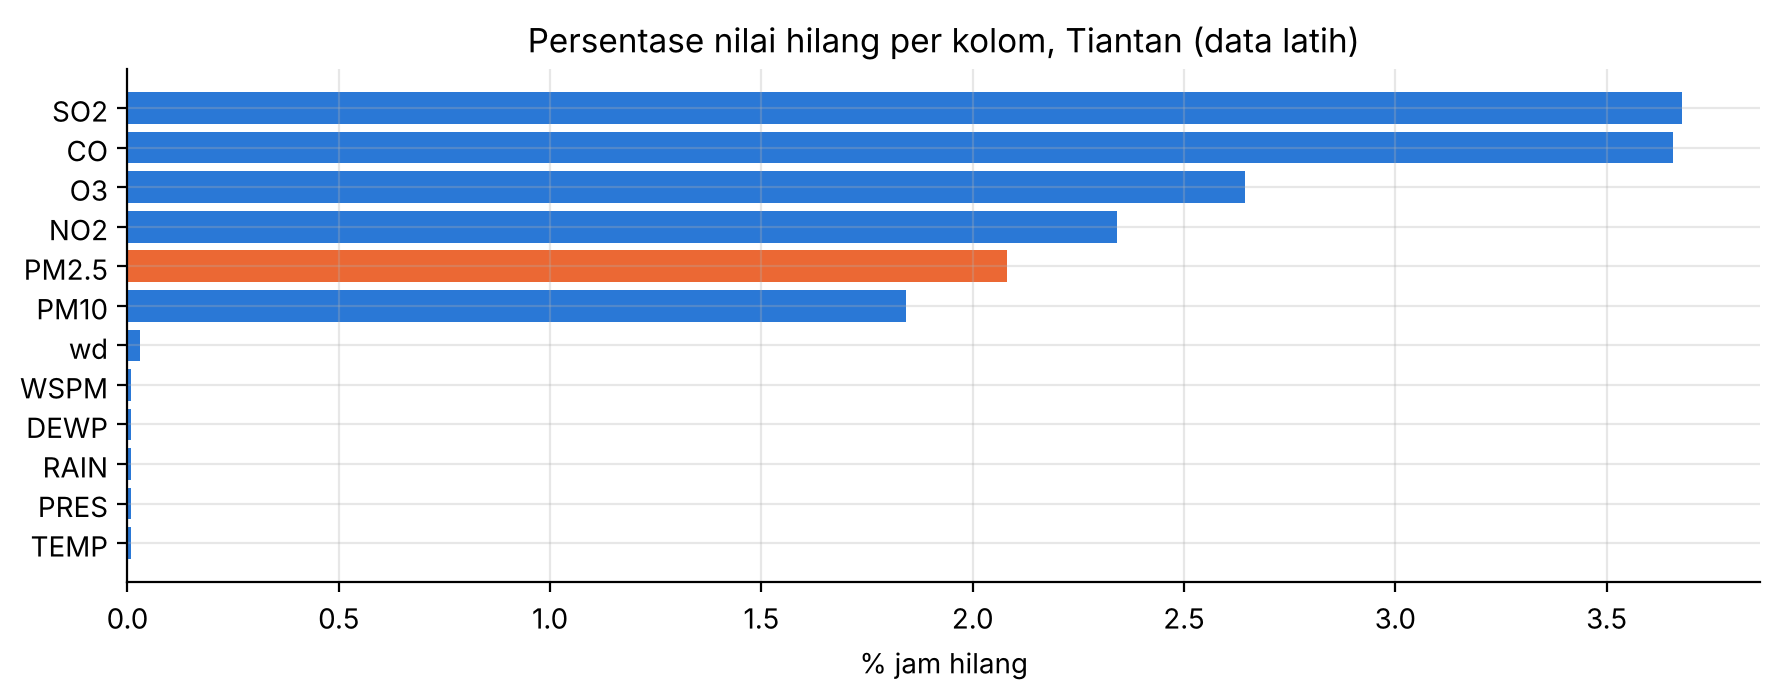

In [10]:
hilang = (tt.drop(columns=["No", "year", "month", "day", "hour", "station"])
            .isna().mean().mul(100).sort_values())
fig, ax = plt.subplots()
ax.barh(hilang.index, hilang, color=[ORANYE if k == "PM2.5" else BIRU for k in hilang.index])
ax.set(title=f"Persentase nilai hilang per kolom, {STASIUN} (data latih)", xlabel="% jam hilang")
simpan_gambar("t2_04_nilai_hilang_per_kolom.png")
hilang.round(2).to_frame("% hilang").to_csv(os.path.join(TABEL, "t2_tabel_nilai_hilang.csv"))

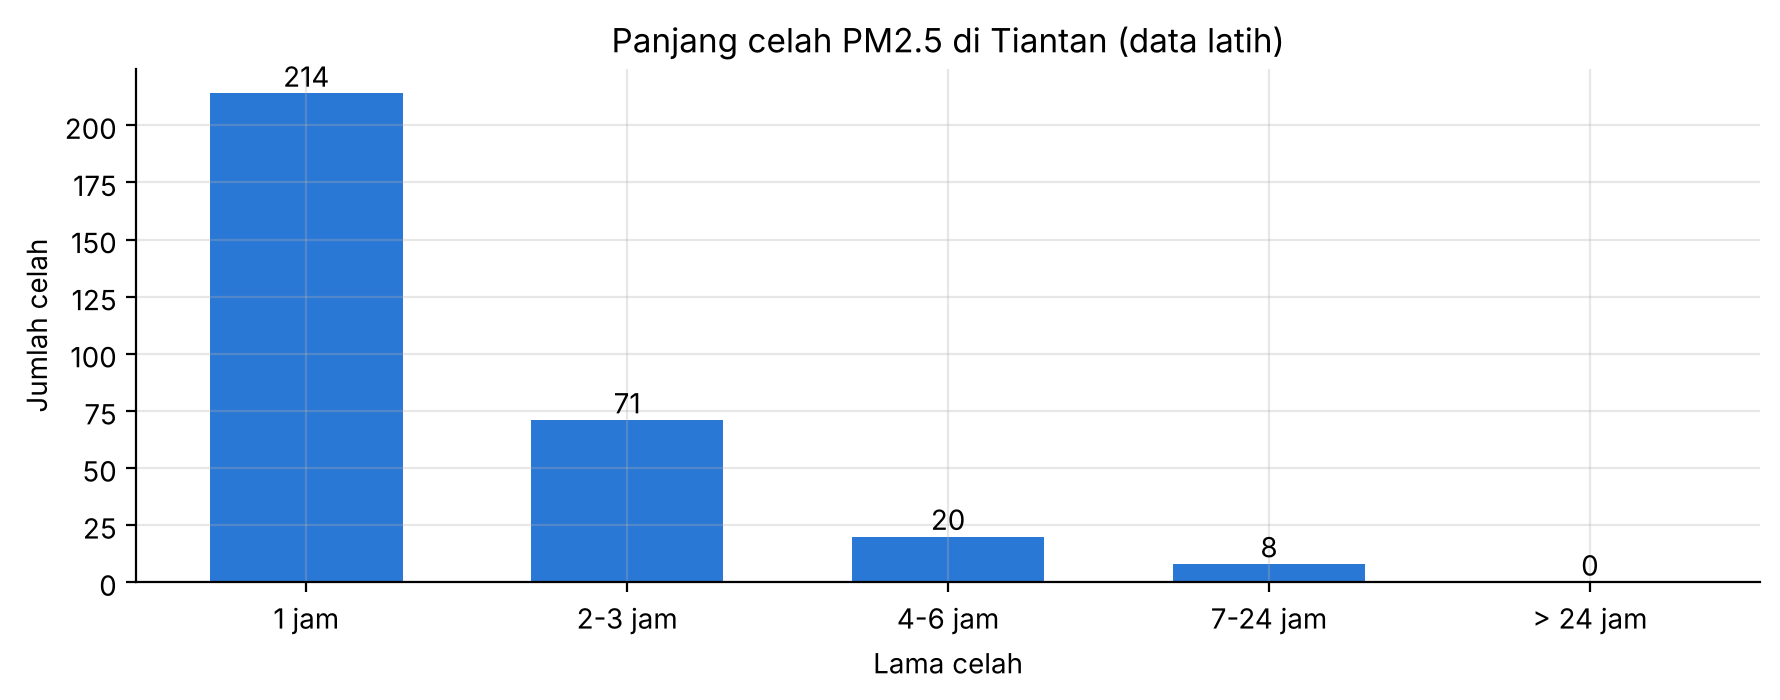

Total celah: 313 | median 1 jam | terpanjang 24 jam
  Celah <= 1 jam: 68% dari celah, 37% dari jam hilang
  Celah <= 3 jam: 91% dari celah, 65% dari jam hilang
  Celah <= 6 jam: 97% dari celah, 80% dari jam hilang


In [11]:
# Panjang setiap celah beruntun pada PM2.5
def panjang_celah(seri):
    kosong = seri.isna()
    kelompok = (kosong != kosong.shift()).cumsum()
    return kosong.groupby(kelompok).sum()[lambda s: s > 0]

celah = panjang_celah(tt["PM2.5"])
kelas = pd.cut(celah, [0, 1, 3, 6, 24, 10_000],
               labels=["1 jam", "2-3 jam", "4-6 jam", "7-24 jam", "> 24 jam"])
hitung = kelas.value_counts().sort_index()

fig, ax = plt.subplots()
ax.bar(hitung.index.astype(str), hitung, color=BIRU, width=0.6)
for x, y in zip(range(len(hitung)), hitung):
    ax.text(x, y, str(y), ha="center", va="bottom")
ax.set(title=f"Panjang celah PM2.5 di {STASIUN} (data latih)",
       xlabel="Lama celah", ylabel="Jumlah celah")
simpan_gambar("t2_05_panjang_celah.png")

print(f"Total celah: {len(celah)} | median {celah.median():.0f} jam | terpanjang {celah.max()} jam")
for k in [1, 3, 6]:
    print(f"  Celah <= {k} jam: {(celah <= k).mean():.0%} dari celah, "
          f"{celah[celah <= k].sum() / celah.sum():.0%} dari jam hilang")

### 02.8 Apa yang berkaitan dengan PM2.5 besok?
Grafik ini menghitung korelasi antara nilai **sekarang** (jam *t*) dengan PM2.5 **24 jam kemudian**.
Inilah informasi yang benar-benar tersedia saat ramalan dibuat.

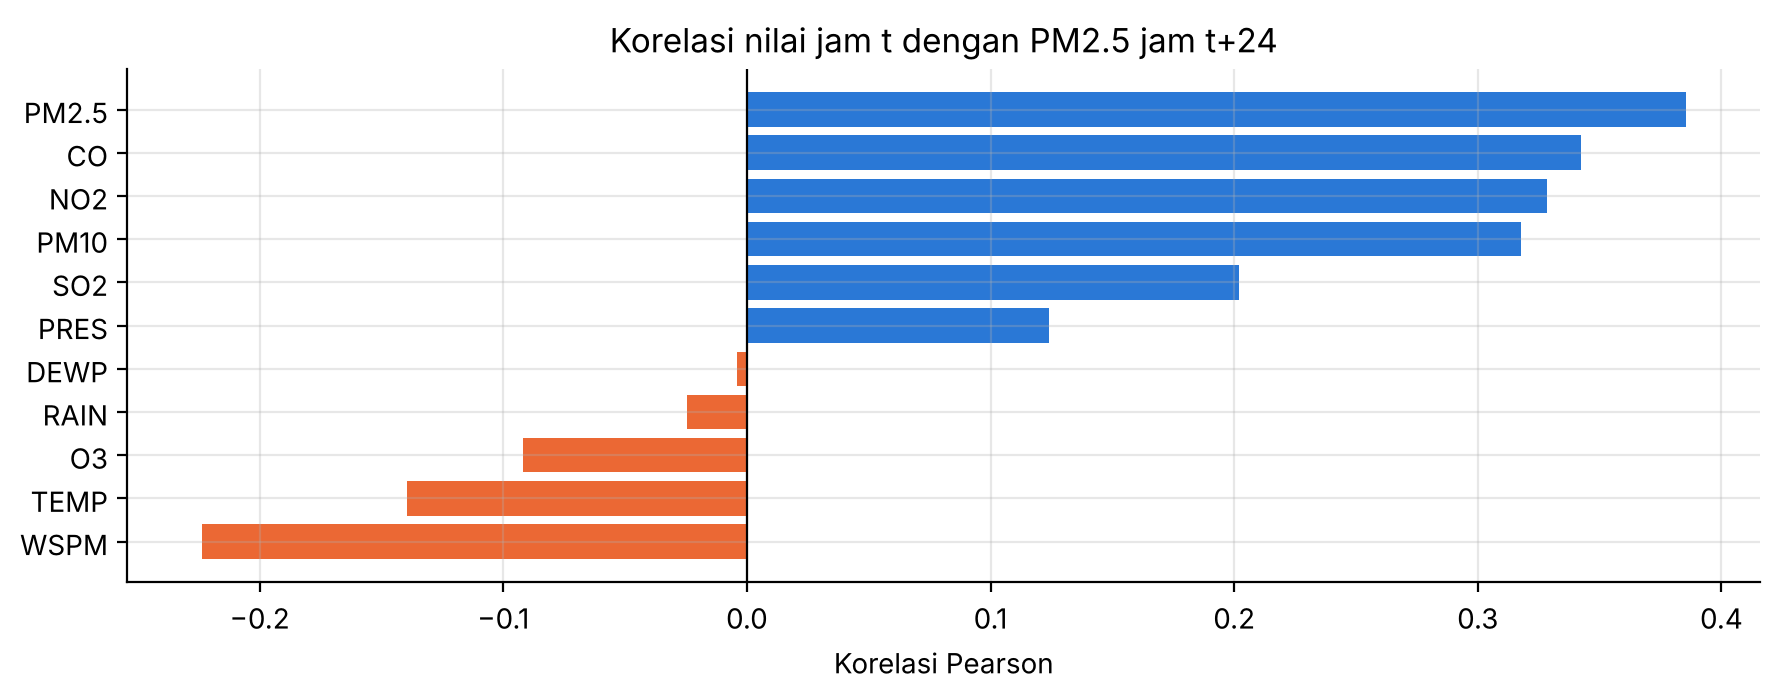

WSPM    -0.224
TEMP    -0.140
O3      -0.092
RAIN    -0.024
DEWP    -0.004
PRES     0.124
SO2      0.202
PM10     0.318
NO2      0.328
CO       0.342
PM2.5    0.385
dtype: float64

In [12]:
kolom_angka = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
target_besok = tt["PM2.5"].shift(-24)        # PM2.5 pada jam t+24
korelasi = tt[kolom_angka].corrwith(target_besok).sort_values()

fig, ax = plt.subplots()
ax.barh(korelasi.index, korelasi, color=[BIRU if v >= 0 else ORANYE for v in korelasi])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Korelasi nilai jam t dengan PM2.5 jam t+24", xlabel="Korelasi Pearson")
simpan_gambar("t2_06_korelasi_dengan_besok.png")
korelasi.round(3)

### 02.9 Seberapa jauh masa lalu masih berguna?
Korelasi PM2.5 besok dengan PM2.5 beberapa jam sebelumnya. Ini membantu memilih *lag* yang dipakai sebagai fitur.

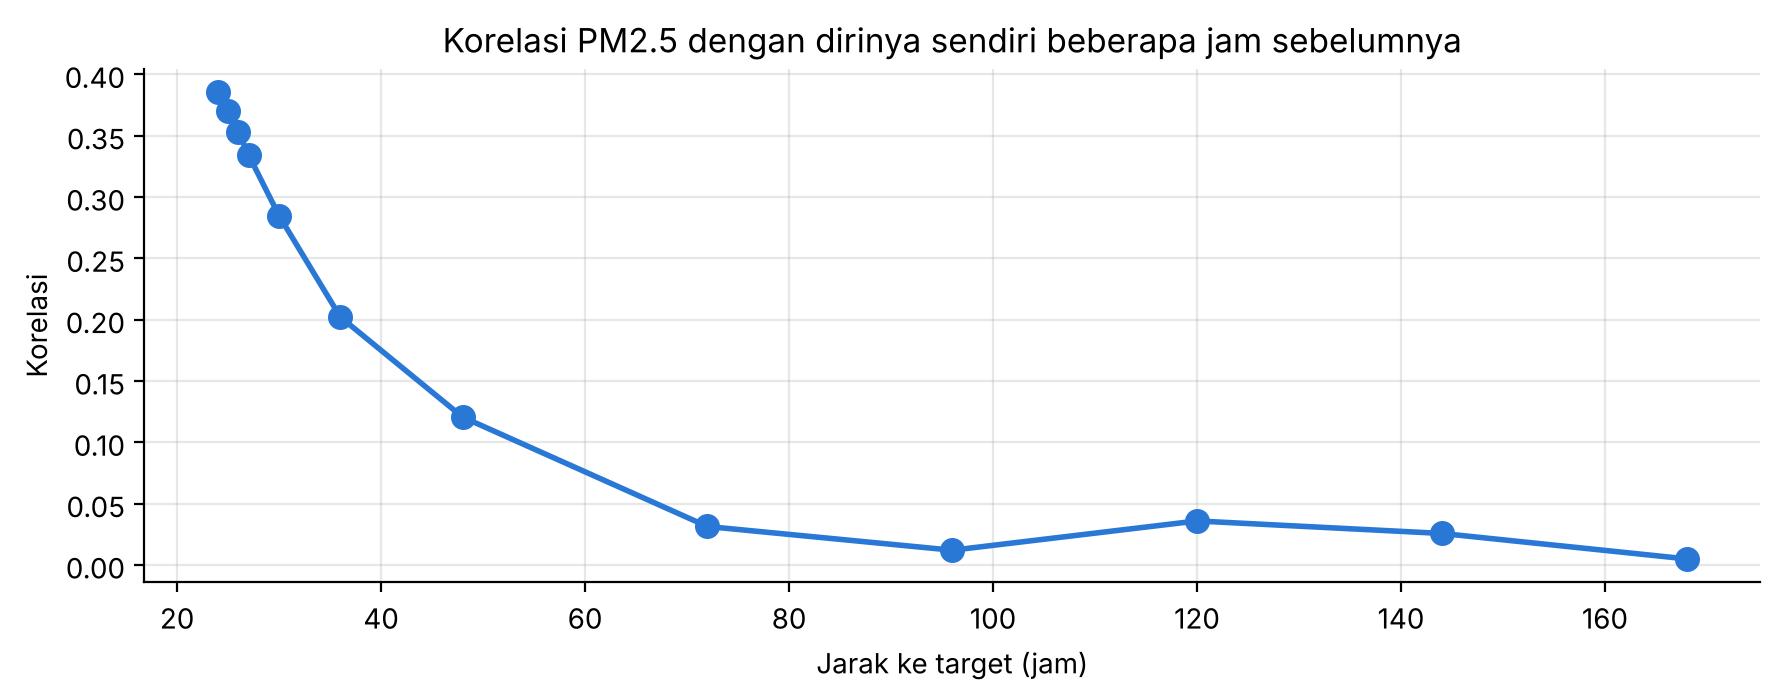

,24,25,26,27,30,36,48,72,96,120,144,168
korelasi,0.385,0.37,0.353,0.334,0.285,0.202,0.12,0.031,0.012,0.036,0.026,0.005


In [13]:
jarak = [24, 25, 26, 27, 30, 36, 48, 72, 96, 120, 144, 168]   # selisih jam dari target
kor_lag = [tt["PM2.5"].corr(tt["PM2.5"].shift(j)) for j in jarak]

fig, ax = plt.subplots()
ax.plot(jarak, kor_lag, color=BIRU, lw=2, marker="o", ms=8)
ax.set(title="Korelasi PM2.5 dengan dirinya sendiri beberapa jam sebelumnya",
       xlabel="Jarak ke target (jam)", ylabel="Korelasi")
simpan_gambar("t2_07_autokorelasi.png")
pd.Series(kor_lag, index=jarak, name="korelasi").round(3).to_frame().T

### 02.10 Perbandingan antarstasiun
Dasar untuk tantangan wajib ketiga: model diuji di stasiun lain. Seberapa beda stasiunnya?

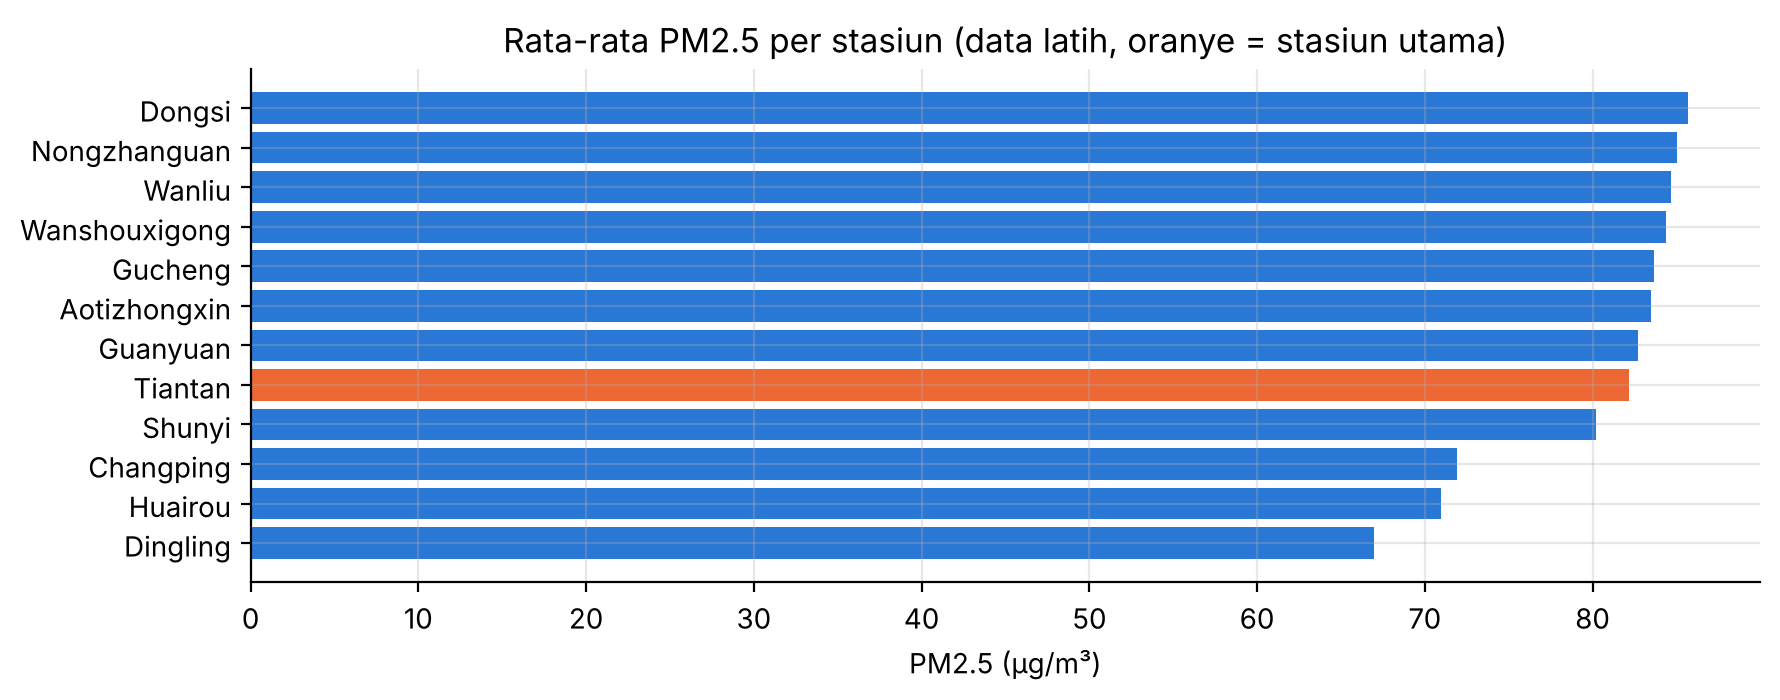

,rata_rata,median,persen_hilang
station,,,
Dingling,67.0,41.0,2.0
Huairou,71.0,48.0,3.1
Changping,71.9,47.0,2.5
Shunyi,80.2,56.0,2.6
Tiantan,82.2,59.0,2.1
Guanyuan,82.7,59.0,1.6
Aotizhongxin,83.5,60.0,2.9
Gucheng,83.7,60.0,1.9
Wanshouxigong,84.4,60.0,1.9


In [14]:
ringkas = (latih.groupby("station")["PM2.5"]
           .agg(rata_rata="mean", median="median", persen_hilang=lambda s: s.isna().mean()*100)
           .sort_values("rata_rata"))
fig, ax = plt.subplots()
ax.barh(ringkas.index, ringkas["rata_rata"],
        color=[ORANYE if s == STASIUN else BIRU for s in ringkas.index])
ax.set(title="Rata-rata PM2.5 per stasiun (data latih, oranye = stasiun utama)",
       xlabel="PM2.5 (µg/m³)")
simpan_gambar("t2_08_rata_rata_per_stasiun.png")
ringkas.round(1).to_csv(os.path.join(TABEL, "t2_tabel_ringkas_stasiun.csv"))
ringkas.round(1)

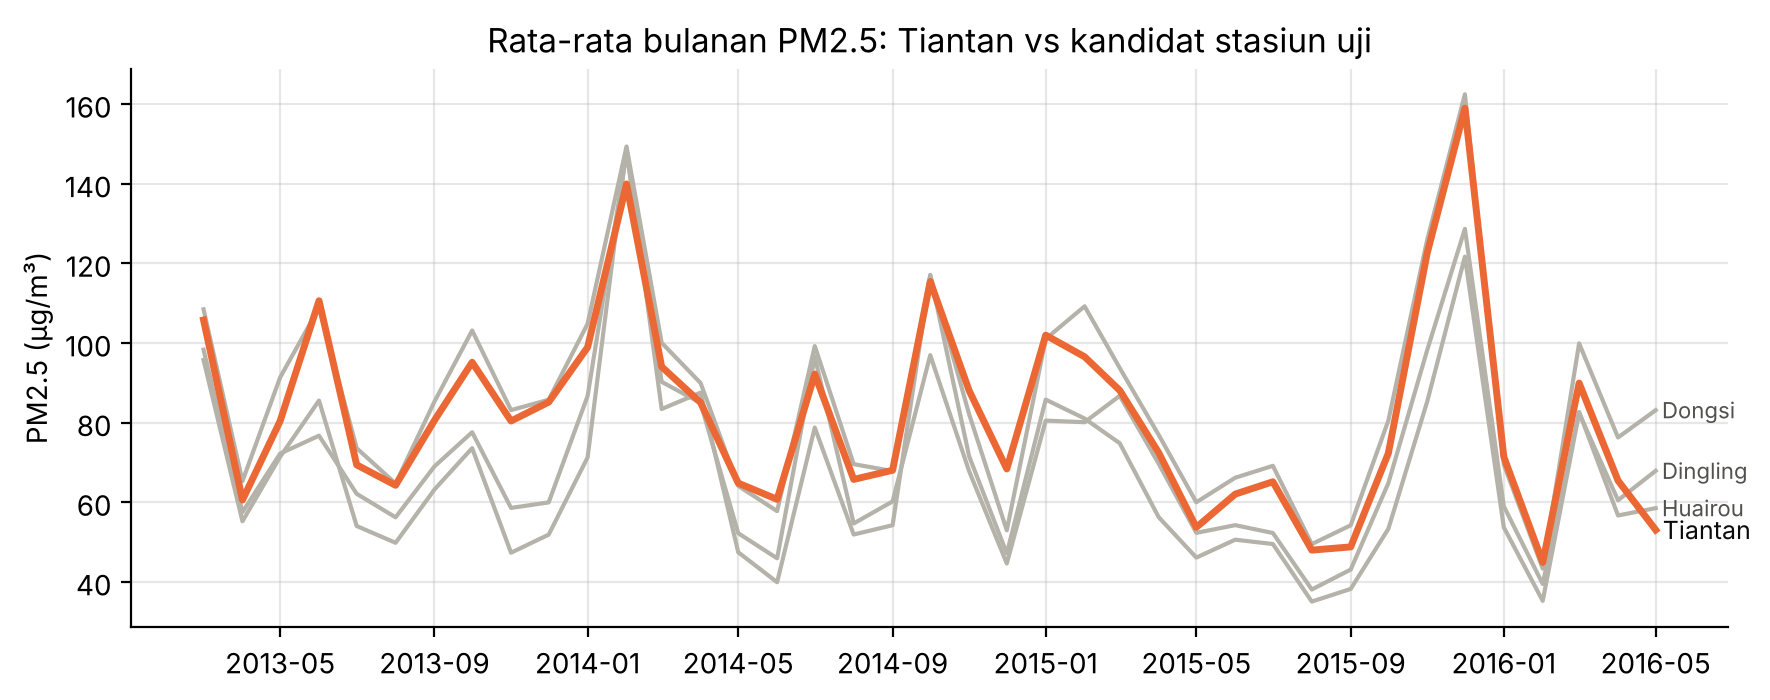

In [15]:
# Pola bulanan Tiantan dibanding kandidat stasiun uji
kandidat = ["Dingling", "Huairou", "Dongsi"]
fig, ax = plt.subplots()
for s in kandidat:
    b = latih[latih["station"] == s].set_index("waktu")["PM2.5"].resample("MS").mean()
    ax.plot(b.index, b, color=ABU, lw=1.5)
    ax.text(b.index[-1], b.iloc[-1], " " + s, color="#52514e", va="center", fontsize=8)
b = tt["PM2.5"].resample("MS").mean()
ax.plot(b.index, b, color=ORANYE, lw=2.5)
ax.text(b.index[-1], b.iloc[-1], " " + STASIUN, color="#0b0b0b", va="center", fontsize=9)
ax.set(title="Rata-rata bulanan PM2.5: Tiantan vs kandidat stasiun uji", ylabel="PM2.5 (µg/m³)")
simpan_gambar("t2_09_bulanan_antarstasiun.png")

## 03. Pembagian data dan skema validasi
Aturan ujian model, sesuai panduan untuk data berurutan waktu:

1. **Data uji** = 20% periode terakhir (sudah disisihkan di 02.2). Disimpan, dan dibuka **satu kali** di akhir proyek.
2. **Data latih** = 80% periode awal. Semua pemilihan model dan *tuning* memakai `TimeSeriesSplit(n_splits=5, gap=24)` di sini.
3. Data **tidak diacak**. Setiap *fold* melatih dengan masa lalu dan memvalidasi dengan periode sesudahnya.
4. **Jarak aman 24 jam** (`gap=24`). Target sebuah baris adalah PM2.5 24 jam sesudahnya. Tanpa jarak, target baris latih terakhir jatuh di periode validasi, padahal nilai itu juga muncul sebagai fitur *lag* di data validasi. Jarak 24 jam menutup celah ini.

Sel di bawah memeriksa aturan nomor 3 dan 4 pada data latih Tiantan.

In [16]:
from sklearn.model_selection import TimeSeriesSplit
cv = TimeSeriesSplit(n_splits=5, gap=24)

# Hanya jam yang targetnya (t+24) masih di periode latih, sama dengan baris yang dipakai model
waktu_latih = tt.index[tt.index + pd.Timedelta(hours=24) < BATAS]
for i, (a, b) in enumerate(cv.split(waktu_latih), 1):
    assert waktu_latih[a].max() + pd.Timedelta(hours=24) < waktu_latih[b].min()   # validasi lebih baru, ada jarak 24 jam
    print(f"Fold {i}: latih s.d. {waktu_latih[a[-1]]:%Y-%m-%d} | "
          f"validasi {waktu_latih[b[0]]:%Y-%m-%d} s.d. {waktu_latih[b[-1]]:%Y-%m-%d}")
print("Data uji mulai", BATAS, "(tidak dipakai di fold mana pun)")

Fold 1: latih s.d. 2013-09-10 | validasi 2013-09-11 s.d. 2014-03-25
Fold 2: latih s.d. 2014-03-24 | validasi 2014-03-25 s.d. 2014-10-05
Fold 3: latih s.d. 2014-10-04 | validasi 2014-10-05 s.d. 2015-04-18
Fold 4: latih s.d. 2015-04-17 | validasi 2015-04-18 s.d. 2015-10-30
Fold 5: latih s.d. 2015-10-29 | validasi 2015-10-30 s.d. 2016-05-11
Data uji mulai 2016-05-12 19:00:00 (tidak dipakai di fold mana pun)


### 03.1 Mengapa skema ini
| Pilihan | Alasan |
|---|---|
| Uji = 20% jam terakhir, tanpa diacak | Data berurutan waktu. Bila diacak, model "mengintip" masa depan. Panduan menetapkan skema ini untuk struktur data seperti ini. |
| `TimeSeriesSplit`, jendela latih melebar | Tiap *fold* melatih dengan semua masa lalu yang ada dan memvalidasi dengan periode sesudahnya, persis seperti pemakaian nyata (meramal ke depan). |
| 5 *fold* | Contoh di panduan. Tiap *fold* validasi sekitar enam setengah bulan, bergantian mencakup musim dingin (*fold* 1, 3, 5) dan musim hangat (*fold* 2, 4), jadi satu skor tidak hanya mewakili satu musim. |
| `gap=24` | Target sebuah baris adalah PM2.5 24 jam sesudahnya. Tanpa jarak, target baris latih terakhir jatuh di periode validasi. |
| Data uji dibuka satu kali | Setiap keputusan (fitur, model, pengaturan) dibuat dari validasi data latih. Skor uji hanya dilaporkan, tidak dipakai untuk menyetel ulang. |

Risiko kebocoran dan penjagaannya:

| Risiko | Penjagaan di *notebook* |
|---|---|
| Fitur memakai nilai masa depan | Fitur hanya sampai jam *t*, tanpa interpolasi (04.1) |
| Target latih jatuh di periode uji | Baris latih 24 jam terakhir dibuang, dicek dengan `assert` (04.2) |
| Target latih jatuh di periode validasi | `gap=24`, dicek dengan `assert` (03 dan 04.5) |
| Praproses belajar dari data validasi atau uji | Imputer dan *scaler* di dalam *pipeline*, dilatih ulang tiap *fold* (04.3, 04.5) |
| Data uji dipakai berulang | Disisihkan di 02.2, dibuka satu kali di tahap 7 lewat penjaga di 03.3 |

### 03.2 Keterbatasan skema ini
* **Lima *fold* itu sedikit.** Simpangan baku RMSE antar *fold* besar (lihat 04.5), jadi selisih kecil antar model tidak boleh dianggap nyata.
* **Periode uji hanya sekitar 9,5 bulan** (2016-05-12 sampai 2017-02-28), tanpa Maret sampai awal Mei. Skor uji belum tentu mewakili satu siklus musim penuh.
* **Hanya satu pembagian uji.** Skor uji adalah satu hasil, bukan rata-rata dari beberapa periode.
* **Uji di stasiun lain memakai periode yang sama dengan uji utama,** sehingga pengaruh pindah stasiun tidak dipisahkan dari pengaruh pindah waktu.
* **Beda skor antar *fold* belum diuji penyebabnya.** *Fold* 1, 3, 5 (musim dingin) lebih tinggi RMSE-nya, tetapi musim hanya salah satu dugaan.

### 03.3 Penjaga data uji
Berkas fitur uji hanya boleh dibaca lewat fungsi di bawah (dipakai nanti di tahap 7). Fungsi ini **tidak dijalankan di sini**.

* Pembukaan pertama dicatat di `Hasil/Tabel/log_pembukaan_data_uji.csv`: waktu, nama berkas, *hash* berkas, *hash* konfigurasi model, dan alasan.
* Membaca ulang dengan konfigurasi model yang **sama** diizinkan, supaya *notebook* tetap bisa dijalankan ulang dari awal.
* Membuka lagi dengan konfigurasi yang **berbeda** ditolak. Itu tanda model disetel ulang setelah melihat skor uji.

**Batas penjaga ini [jujur]:** hanya mencegah pembukaan ganda yang tidak disengaja. Orang yang menghapus baris log atau mengubah fungsi tetap bisa melewatinya, dan fungsi tidak bisa tahu apakah konfigurasi dipilih dari validasi atau dari skor uji. Aturan pemilihan model ada di `Laporan/Protokol Evaluasi Data Uji.md`, dan log ini baru berarti kalau di-*commit* bersama versi kode model yang dibekukan.

In [17]:
import json, hashlib

LOG_UJI = os.path.join(TABEL, "log_pembukaan_data_uji.csv")
KOLOM_LOG = ["waktu", "berkas", "sha256_berkas", "sha256_konfigurasi", "alasan"]

def _sha(b):
    return hashlib.sha256(b).hexdigest()

def buka_data_uji(jalur, konfigurasi, alasan, log=LOG_UJI):
    """Satu-satunya pintu membaca berkas fitur uji. konfigurasi = dict hiperparameter, daftar fitur, dan praproses model final."""
    nama = os.path.basename(jalur)
    sha_konf = _sha(json.dumps(konfigurasi, sort_keys=True, default=str).encode())
    sha_berkas = _sha(open(jalur, "rb").read())
    riwayat = pd.read_csv(log) if os.path.exists(log) else pd.DataFrame(columns=KOLOM_LOG)
    lalu = riwayat[riwayat["berkas"] == nama]
    if len(lalu) == 0:
        baris = pd.DataFrame([[pd.Timestamp.now().isoformat(timespec="seconds"), nama,
                               sha_berkas, sha_konf, alasan]], columns=KOLOM_LOG)
        pd.concat([riwayat, baris], ignore_index=True).to_csv(log, index=False)
        print(f"Data uji {nama} dibuka untuk pertama kali dan dicatat.")
    elif sha_konf in set(lalu["sha256_konfigurasi"]):
        print(f"Data uji {nama} sudah pernah dibuka dengan konfigurasi yang sama: dibaca ulang untuk reproduksi.")
        if sha_berkas not in set(lalu["sha256_berkas"]):
            print("PERINGATAN: isi berkas berbeda dari saat pertama dibuka (cek versi pustaka atau apakah berkas dibuat ulang).")
    else:
        raise RuntimeError(f"{nama} sudah pernah dibuka dengan konfigurasi model yang lain. "
                           "Menyetel ulang model setelah melihat skor uji tidak diizinkan; laporkan skor pertama apa adanya.")
    return pd.read_csv(jalur, index_col=0, parse_dates=True)

print("Penjaga data uji siap. Belum ada berkas uji yang dibuka." if not os.path.exists(LOG_UJI)
      else "Log pembukaan data uji sudah ada:", LOG_UJI if os.path.exists(LOG_UJI) else "")

Penjaga data uji siap. Belum ada berkas uji yang dibuka. 


## 04. Fitur dan *pipeline* praproses
### 04.1 Siapkan fitur
Setiap baris = satu jam *t*. **Target** = PM2.5 pada jam *t+24*.
Semua fitur hanya memakai data sampai jam *t*.

| Kelompok | Isi |
|---|---|
| Kondisi sekarang | polutan dan cuaca pada jam *t* |
| *Lag* | PM2.5 beberapa jam sebelumnya |
| *Rolling mean* | rata-rata PM2.5 6, 24, dan 72 jam terakhir |
| Kalender | jam, hari dalam pekan, bulan (dalam bentuk sin dan cos agar jam 23 dekat dengan jam 0) |
| Angin | arah angin diubah menjadi sin dan cos |

**Nilai hilang [Usulan, bukan aturan dosen]:**
* Target hilang: baris dibuang, tidak diisi tebakan.
* Fitur hilang: **tidak diisi di sini** (tanpa *forward fill*). Semua yang kosong diurus imputer median di dalam *pipeline* (04.3), yang hanya belajar dari data latih tiap *fold*.

Mengapa tanpa *forward fill*? Pada validasi data latih Tiantan (5 *fold*, dua model), pengisian 0, 1, 3, 6, 12, dan 24 jam tidak memberi beda yang bisa dibedakan dari derau antar *seed*, jadi dipilih yang paling sederhana. Perbandingannya ada di 04.6.

In [18]:
FFILL_MAKS = 0      # batas forward fill (jam). 0 = tanpa pengisian (keputusan 15 Nov 2026)
ARAH = {a: i * 22.5 for i, a in enumerate(
    ["N","NNE","NE","ENE","E","ESE","SE","SSE","S","SSW","SW","WSW","W","WNW","NW","NNW"])}

def buat_fitur(data_stasiun):
    d = data_stasiun.set_index("waktu").sort_index()
    f = pd.DataFrame(index=d.index)

    # Target: PM2.5 asli 24 jam ke depan (tanpa pengisian)
    f["target"] = d["PM2.5"].shift(-24)

    # Kondisi sekarang. Bila FFILL_MAKS > 0, celah pendek diisi nilai terakhir (hanya melihat ke belakang)
    isi = d[kolom_angka].ffill(limit=FFILL_MAKS) if FFILL_MAKS > 0 else d[kolom_angka]
    for k in kolom_angka:
        f[k] = isi[k]

    # Lag dan rolling mean PM2.5 (shift positif = masa lalu)
    for j in [1, 2, 3, 6, 12, 24, 48]:
        f[f"PM2.5_lag{j}"] = isi["PM2.5"].shift(j)
    for w in [6, 24, 72]:
        f[f"PM2.5_rata{w}j"] = isi["PM2.5"].rolling(w, min_periods=w // 2).mean()

    # Kalender dan arah angin dalam bentuk lingkaran
    wd = d["wd"].ffill(limit=FFILL_MAKS) if FFILL_MAKS > 0 else d["wd"]
    sudut = wd.map(ARAH)
    f["angin_sin"], f["angin_cos"] = np.sin(np.radians(sudut)), np.cos(np.radians(sudut))
    f["jam_sin"], f["jam_cos"] = np.sin(2*np.pi*d.index.hour/24), np.cos(2*np.pi*d.index.hour/24)
    f["hari_sin"], f["hari_cos"] = np.sin(2*np.pi*d.index.dayofweek/7), np.cos(2*np.pi*d.index.dayofweek/7)
    f["bulan_sin"], f["bulan_cos"] = np.sin(2*np.pi*d.index.month/12), np.cos(2*np.pi*d.index.month/12)
    return f

### 04.2 Potong fitur di batas data uji
Fitur dibuat dari deret lengkap (karena hanya melihat ke belakang, ini aman), lalu dipotong di `BATAS`.

**Celah kebocoran yang ditutup:** baris latih 24 jam terakhir punya target yang jatuh di periode uji.
Baris itu dibuang supaya tidak ada nilai uji yang ikut dilatih.

In [19]:
fitur = buat_fitur(df[df["station"] == STASIUN])
waktu_target = fitur.index + pd.Timedelta(hours=24)

fitur_latih = fitur[(waktu_target < BATAS)].dropna(subset=["target"])
fitur_uji   = fitur[(fitur.index >= BATAS)].dropna(subset=["target"])

print(f"Fitur latih: {fitur_latih.shape[0]:,} baris, {fitur_latih.shape[1]-1} fitur")
print(f"Fitur uji  : {fitur_uji.shape[0]:,} baris (disimpan, tidak dibuka)")
print("Target latih terakhir:", (fitur_latih.index.max() + pd.Timedelta(hours=24)),
      "| harus sebelum", BATAS)
assert fitur_latih.index.max() + pd.Timedelta(hours=24) < BATAS

Fitur latih: 27,443 baris, 29 fitur
Fitur uji  : 6,896 baris (disimpan, tidak dibuka)
Target latih terakhir: 2016-05-12 18:00:00 | harus sebelum 2016-05-12 19:00:00


In [20]:
# Cek: berapa persen fitur yang masih kosong (tanpa pengisian, diurus imputer di pipeline)
sisa = fitur_latih.drop(columns="target").isna().mean().mul(100)
print(f"Fitur dengan nilai kosong tersisa: {(sisa > 0).sum()} dari {len(sisa)}, "
      f"tertinggi {sisa.idxmax()} = {sisa.max():.2f}%")

Fitur dengan nilai kosong tersisa: 23 dari 29, tertinggi CO = 3.20%


### 04.3 *Pipeline* praproses
Langkah yang "belajar" dari data (mengisi kosong dengan median, menyamakan skala) ditaruh di dalam *pipeline*.
*Pipeline* ini dilatih ulang di setiap *fold* `TimeSeriesSplit`, jadi hanya belajar dari data latih *fold* itu.

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Belum dilatih di sini. Di tahap 4, pipeline ini dilatih ulang di setiap fold (cv dari bagian 03).
praproses = Pipeline([("isi_kosong", SimpleImputer(strategy="median")),
                      ("skala", StandardScaler())])
praproses

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('isi_kosong', ...), ('skala', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account 

### 04.4 Simpan hasil

In [22]:
fitur_latih.to_csv(os.path.join(OLAHAN, f"fitur_latih_{STASIUN}.csv"))
fitur_uji.to_csv(os.path.join(OLAHAN, f"fitur_uji_{STASIUN}.csv"))
for nama_folder, isi in (("Gambar", GAMBAR), ("Tabel", TABEL), ("Fitur", OLAHAN)):
    print(f"{nama_folder}:", ", ".join(sorted(os.listdir(isi))))

Gambar: README.md, t2_01_sebaran_pm25.png, t2_02_deret_waktu_harian.png, t2_03_pola_jam_bulan.png, t2_04_nilai_hilang_per_kolom.png, t2_05_panjang_celah.png, t2_06_korelasi_dengan_besok.png, t2_07_autokorelasi.png, t2_08_rata_rata_per_stasiun.png, t2_09_bulanan_antarstasiun.png, t4_01_baseline_rmse_per_fold.png
Tabel: README.md, t2_tabel_nilai_hilang.csv, t2_tabel_ringkas_stasiun.csv, t4_tabel_baseline.csv
Fitur: README.md, fitur_latih_Tiantan.csv, fitur_uji_Tiantan.csv


### 04.5 *Baseline* (hasil *cross-validation*)
*Baseline* adalah titik acuan. Tanpanya, sebuah angka RMSE tidak bermakna.

| Model | Isi | Asal |
|---|---|---|
| *Naive forecast* | PM2.5 24 jam lagi dianggap sama dengan PM2.5 sekarang | Wajib untuk deret waktu (panduan) |
| Regresi linear | *Pipeline* 04.3 + regresi linear pada semua fitur | Pembanding tambahan [Usulan] |

Aturan evaluasi:
* `TimeSeriesSplit(n_splits=5, gap=24)` pada **data latih** saja. Data uji tidak disentuh.
* *Naive forecast* butuh PM2.5 jam *t*. Baris validasi yang PM2.5 jam *t*-nya kosong dibuang dari **kedua** model supaya dibandingkan pada baris yang sama.
* Hasil dilaporkan sebagai rata-rata ± simpangan baku antar *fold*. RMSE jadi metrik utama, MAE pendamping.

In [23]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression

X = fitur_latih.drop(columns="target")
y = fitur_latih["target"]
cv = TimeSeriesSplit(n_splits=5, gap=24)          # jarak aman 24 jam (lihat bagian 03)

def rmse(y_asli, y_tebak): return float(np.sqrt(np.mean((y_asli - y_tebak) ** 2)))
def mae(y_asli, y_tebak):  return float(np.mean(np.abs(y_asli - y_tebak)))

nama_model = ["Naive forecast", "Regresi linear"]
skor = {n: {"RMSE": [], "MAE": []} for n in nama_model}
dibuang = jumlah_validasi = 0
for a, b in cv.split(X):
    # target baris latih harus jatuh sebelum periode validasi dimulai
    assert X.index[a].max() + pd.Timedelta(hours=24) < X.index[b].min()
    ada = X.iloc[b]["PM2.5"].notna().to_numpy()      # naive butuh PM2.5 jam t
    dibuang += int((~ada).sum()); jumlah_validasi += len(b)
    Xv, yv = X.iloc[b][ada], y.iloc[b][ada].to_numpy()

    tebak = {"Naive forecast": Xv["PM2.5"].to_numpy()}
    model = Pipeline([("praproses", clone(praproses)), ("model", LinearRegression())])
    tebak["Regresi linear"] = model.fit(X.iloc[a], y.iloc[a]).predict(Xv)

    for n in nama_model:
        skor[n]["RMSE"].append(rmse(yv, tebak[n]))
        skor[n]["MAE"].append(mae(yv, tebak[n]))

tabel_baseline = pd.DataFrame({
    "RMSE rata-rata": [np.mean(skor[n]["RMSE"]) for n in nama_model],
    "RMSE sd":        [np.std(skor[n]["RMSE"], ddof=1) for n in nama_model],
    "MAE rata-rata":  [np.mean(skor[n]["MAE"]) for n in nama_model],
    "MAE sd":         [np.std(skor[n]["MAE"], ddof=1) for n in nama_model]}, index=nama_model).round(2)
tabel_baseline.to_csv(os.path.join(TABEL, "t4_tabel_baseline.csv"))
print(f"Baris validasi dibuang (PM2.5 jam t kosong): {dibuang} dari {jumlah_validasi:,}")
print("RMSE per fold:")
for n in nama_model:
    print(f"  {n:<15}", np.round(skor[n]["RMSE"], 1))
tabel_baseline

Baris validasi dibuang (PM2.5 jam t kosong): 428 dari 22,865
RMSE per fold:
  Naive forecast  [101.3  63.  103.5  56.5 110.6]
  Regresi linear  [85.5 54.7 80.9 50.5 95.3]


,RMSE rata-rata,RMSE sd,MAE rata-rata,MAE sd
Naive forecast,86.97,25.19,59.96,16.96
Regresi linear,73.38,19.73,55.20,12.73


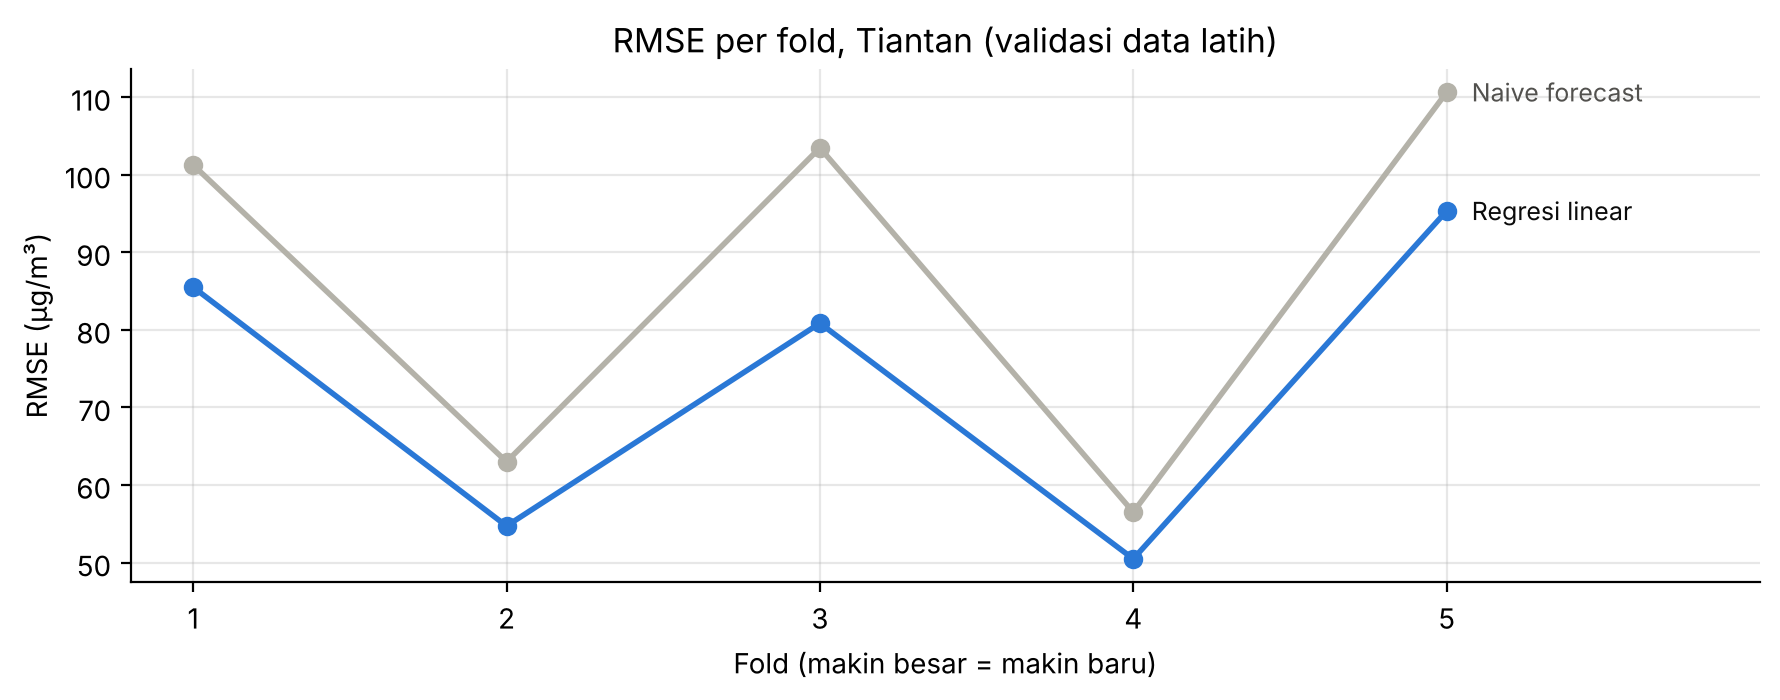

In [24]:
fig, ax = plt.subplots()
fold = np.arange(1, 6)
ax.plot(fold, skor["Naive forecast"]["RMSE"], marker="o", lw=2, color=ABU)
ax.plot(fold, skor["Regresi linear"]["RMSE"], marker="o", lw=2, color=BIRU)
ax.text(5.08, skor["Naive forecast"]["RMSE"][-1], "Naive forecast", color="#52514e", va="center", fontsize=9)
ax.text(5.08, skor["Regresi linear"]["RMSE"][-1], "Regresi linear", color="#0b0b0b", va="center", fontsize=9)
ax.set(title=f"RMSE per fold, {STASIUN} (validasi data latih)", xlabel="Fold (makin besar = makin baru)",
       ylabel="RMSE (µg/m³)", xticks=fold, xlim=(0.8, 6.0))
simpan_gambar("t4_01_baseline_rmse_per_fold.png")

### 04.6 Dasar keputusan: batas *forward fill*
Keputusan 15 Nov 2026: tanpa *forward fill*. Di sini dasarnya dihitung ulang, **hanya dari data latih** (data uji tidak dipakai). Fitur dibuat ulang dengan batas pengisian 0, 1, 3, 6, 12, dan 24 jam, lalu dua model dinilai dengan `TimeSeriesSplit(n_splits=5, gap=24)` di Tiantan.
Karena celah pendek diisi nilai terakhir (hanya melihat ke belakang), tidak ada nilai masa depan yang masuk.

Yang dibandingkan adalah selisih antar pengaturan *dan* derau antar *seed* pada pengaturan yang sama. Selisih yang lebih kecil dari derau tidak boleh dianggap nyata.

In [25]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

def fitur_dengan_ffill(data_stasiun, ff):
    global FFILL_MAKS
    simpan, FFILL_MAKS = FFILL_MAKS, ff
    try:
        f = buat_fitur(data_stasiun)
    finally:
        FFILL_MAKS = simpan
    f["_pm_t"] = data_stasiun.set_index("waktu").sort_index()["PM2.5"]   # hanya untuk naive, bukan fitur
    return f

def model_uji(nama, seed=SEED):
    reg = Ridge(alpha=1.0) if nama == "Ridge" else HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.1, max_depth=4, random_state=seed)
    return Pipeline([("isi", SimpleImputer(strategy="median")), ("skala", StandardScaler()), ("m", reg)])

# Lipatan dibuat dari seluruh jam periode latih yang targetnya (jam t+24) jatuh sebelum BATAS
jam_cv = pd.DatetimeIndex(np.sort(latih["waktu"].unique()))
jam_cv = jam_cv[jam_cv < BATAS - pd.Timedelta(hours=24)]
lipatan = [(jam_cv[a], jam_cv[b]) for a, b in TimeSeriesSplit(n_splits=5, gap=24).split(jam_cv)]
for a, b in lipatan:
    assert a.max() + pd.Timedelta(hours=24) < b.min()

def baris_fold(F, jam):
    x = F.loc[F.index.isin(jam)].dropna(subset=["target"])
    return x.drop(columns=["target", "_pm_t"]), x["target"]

latih_per_stasiun = {s: g for s, g in latih.groupby("station")}
latih_tt = latih_per_stasiun[STASIUN]
daftar_ff = [0, 1, 3, 6, 12, 24]
skor_ff = {}
for ff in daftar_ff:
    F = fitur_dengan_ffill(latih_tt, ff)
    for nm in ["Ridge", "HGB"]:
        r = []
        for a, b in lipatan:
            Xa, ya = baris_fold(F, a); Xb, yb = baris_fold(F, b)
            r.append(rmse(yb, model_uji(nm).fit(Xa, ya).predict(Xb)))
        skor_ff[(ff, nm)] = np.array(r)

baris_tabel = []
for nm in ["Ridge", "HGB"]:
    dasar = skor_ff[(3, nm)]
    for ff in daftar_ff:
        r = skor_ff[(ff, nm)]
        baris_tabel.append({"model": nm, "ffill_maks_jam": ff, "RMSE rata-rata": r.mean(), "RMSE sd antar fold": r.std(ddof=1),
                            "selisih vs 3 jam": (r - dasar).mean(), "fold lebih baik dari 3 jam": int(((r - dasar) < 0).sum())})
tabel_ff = pd.DataFrame(baris_tabel).round(3)
tabel_ff.to_csv(os.path.join(TABEL, "t2_tabel_ffill.csv"), index=False)
tabel_ff

,model,ffill_maks_jam,RMSE rata-rata,RMSE sd antar fold,selisih vs 3 jam,fold lebih baik dari 3 jam
0,Ridge,0,73.491,19.871,0.029,1
1,Ridge,1,73.491,19.871,0.029,2
2,Ridge,3,73.462,19.891,0.000,0
3,Ridge,6,73.429,19.914,-0.033,4
4,Ridge,12,73.429,19.924,-0.033,4
5,Ridge,24,73.423,19.900,-0.039,4
6,HGB,0,76.834,22.004,-0.300,2
7,HGB,1,76.846,21.913,-0.288,3
8,HGB,3,77.134,22.363,0.000,0
9,HGB,6,76.811,21.861,-0.323,2


In [26]:
# Lantai derau: pengaturan yang sama (ffill = 3 jam), hanya seed HGB yang diganti
F3 = fitur_dengan_ffill(latih_tt, 3)
rata_seed = []
for sd in range(6):
    r = []
    for a, b in lipatan:
        Xa, ya = baris_fold(F3, a); Xb, yb = baris_fold(F3, b)
        r.append(rmse(yb, model_uji("HGB", seed=sd).fit(Xa, ya).predict(Xb)))
    rata_seed.append(np.mean(r))
rentang_seed = max(rata_seed) - min(rata_seed)
rentang_ff = {nm: np.ptp([skor_ff[(ff, nm)].mean() for ff in daftar_ff]) for nm in ["Ridge", "HGB"]}
print("RMSE rata-rata per seed HGB (ffill = 3 jam):", np.round(rata_seed, 2), "| rentang", round(rentang_seed, 2))
print("Rentang rata-rata RMSE antar pengaturan ffill:", {k: round(float(v), 2) for k, v in rentang_ff.items()})
print("Ridge: selisih antar pengaturan jauh lebih kecil dari simpangan baku antar fold. HGB: bandingkan dengan rentang seed di atas.")

RMSE rata-rata per seed HGB (ffill = 3 jam): [77.03 76.82 76.67 77.2  76.89 77.27] | rentang 0.6
Rentang rata-rata RMSE antar pengaturan ffill: {'Ridge': 0.07, 'HGB': 0.53}
Ridge: selisih antar pengaturan jauh lebih kecil dari simpangan baku antar fold. HGB: bandingkan dengan rentang seed di atas.


### 04.7 Dasar keputusan: stasiun uji
Keputusan 15 Nov 2026: stasiun uji = Dingling. Dasarnya dihitung ulang di sini, **hanya dari data latih**. Dua pertanyaan terpisah:
1. Stasiun mana yang distribusi PM2.5-nya paling berbeda dari Tiantan? (statistik distribusi)
2. Apakah itu membuat model dari Tiantan lebih buruk di sana? (uji transfer pada lipatan yang sama)

Dua pertanyaan itu bisa berjawaban berbeda: distribusi yang berbeda belum tentu lebih sulit diramal.

In [27]:
from scipy.stats import ks_2samp, wasserstein_distance

acuan = latih_tt["PM2.5"].dropna().values
tab_dist = []
for s, g in latih.groupby("station"):
    v = g["PM2.5"].dropna().values
    tab_dist.append(dict(stasiun=s, rata_rata=v.mean(), median=np.median(v), sd=v.std(), kuantil90=np.quantile(v, .9),
                         hilang_pct=100 * g["PM2.5"].isna().mean(),
                         KS=ks_2samp(v, acuan).statistic, wasserstein=wasserstein_distance(v, acuan)))
tab_dist = pd.DataFrame(tab_dist).set_index("stasiun")
piv = latih.pivot_table(index="waktu", columns="station", values="PM2.5")
tab_dist["korelasi_dg_Tiantan"] = [piv[s].corr(piv[STASIUN]) for s in tab_dist.index]
tab_dist = tab_dist.round(3).sort_values("wasserstein", ascending=False)
tab_dist.to_csv(os.path.join(TABEL, "t2_tabel_distribusi_stasiun.csv"))
tab_dist

,rata_rata,median,sd,kuantil90,hilang_pct,KS,wasserstein,korelasi_dg_Tiantan
stasiun,,,,,,,,
Dingling,66.990,41.0,73.645,164.0,1.950,0.115,15.211,0.797
Huairou,70.964,48.0,71.727,167.0,3.077,0.073,11.233,0.828
Changping,71.913,47.0,72.164,171.0,2.460,0.074,10.288,0.817
Dongsi,85.698,61.0,85.049,199.0,1.572,0.017,3.842,0.965
Nongzhanguan,85.016,59.0,85.610,197.0,1.882,0.013,2.999,0.954
Wanliu,84.651,60.0,81.860,192.0,1.062,0.016,2.547,0.924
Wanshouxigong,84.396,60.0,84.130,193.0,1.907,0.010,2.379,0.965
Shunyi,80.232,56.0,80.839,186.0,2.592,0.028,2.288,0.883
Gucheng,83.688,60.0,80.852,188.0,1.879,0.016,1.571,0.894


In [28]:
# Uji transfer: model dilatih di Tiantan, divalidasi di stasiun lain pada lipatan yang sama (ffill = 3 jam)
F_st = {s: fitur_dengan_ffill(g, 3) for s, g in latih_per_stasiun.items()}
baris_transfer = []
for nm in ["Ridge", "HGB"]:
    for s in F_st:
        if s == STASIUN: continue
        sendiri, transfer, biaya = [], [], []
        for a, b in lipatan:
            Xa_t, ya_t = baris_fold(F_st[STASIUN], a)
            m_t = model_uji(nm).fit(Xa_t, ya_t)
            Xb, yb = baris_fold(F_st[s], b)
            Xa_s, ya_s = baris_fold(F_st[s], a)
            m_s = model_uji(nm).fit(Xa_s, ya_s)
            r_t, r_s = rmse(yb, m_t.predict(Xb)), rmse(yb, m_s.predict(Xb))
            transfer.append(r_t); sendiri.append(r_s); biaya.append(r_t / r_s - 1)
        baris_transfer.append({"model": nm, "stasiun": s, "RMSE dilatih sendiri": np.mean(sendiri),
                               "RMSE dari Tiantan": np.mean(transfer),
                               "biaya transfer %": 100 * np.mean(transfer) / np.mean(sendiri) - 100,
                               "sd biaya antar fold %": 100 * np.std(biaya, ddof=1)})
tabel_transfer = pd.DataFrame(baris_transfer).round(2).sort_values(["model", "biaya transfer %"], ascending=[True, False])
tabel_transfer.to_csv(os.path.join(TABEL, "t2_tabel_transfer.csv"), index=False)
tabel_transfer

,model,stasiun,RMSE dilatih sendiri,RMSE dari Tiantan,biaya transfer %,sd biaya antar fold %
18,HGB,Nongzhanguan,78.97,81.27,2.92,2.83
20,HGB,Wanliu,77.05,79.20,2.79,2.58
16,HGB,Gucheng,77.94,79.77,2.35,2.00
12,HGB,Changping,68.67,69.76,1.59,1.76
15,HGB,Guanyuan,77.02,77.81,1.03,4.95
11,HGB,Aotizhongxin,79.02,79.08,0.07,4.26
21,HGB,Wanshouxigong,80.83,80.43,-0.49,2.64
17,HGB,Huairou,70.11,69.70,-0.59,8.53
14,HGB,Dongsi,82.33,81.34,-1.21,3.76
19,HGB,Shunyi,78.45,77.29,-1.48,3.13


In [29]:
d = tab_dist.loc[["Dingling", "Huairou", "Dongsi"], ["rata_rata", "wasserstein", "KS", "korelasi_dg_Tiantan"]]
print(f"Tiantan (acuan) rata-rata {acuan.mean():.1f}")
print(d.to_string())
print()
print(tabel_transfer[tabel_transfer["stasiun"] == STASIUN_UJI].to_string(index=False))
print("Baca: biaya transfer yang lebih kecil dari simpangan baku antar fold tidak boleh dianggap nyata.")

Tiantan (acuan) rata-rata 82.2
          rata_rata  wasserstein     KS  korelasi_dg_Tiantan
stasiun                                                     
Dingling     66.990       15.211  0.115                0.797
Huairou      70.964       11.233  0.073                0.828
Dongsi       85.698        3.842  0.017                0.965

model  stasiun  RMSE dilatih sendiri  RMSE dari Tiantan  biaya transfer %  sd biaya antar fold %
  HGB Dingling                 72.25              70.27             -2.74                   5.90
Ridge Dingling                 67.36              67.58              0.33                   1.08
Baca: biaya transfer yang lebih kecil dari simpangan baku antar fold tidak boleh dianggap nyata.


## Ringkasan
Angka di bawah dihitung langsung dari data latih di atas.

In [30]:
print(f"1. Data latih sampai {BATAS - pd.Timedelta(hours=1)}, data uji mulai {BATAS} (tidak dibuka).")
print(f"2. PM2.5 {STASIUN}: median {pm.median():.0f}, rata-rata {pm.mean():.0f}, miring ke kanan "
      f"(skewness {pm.skew():.2f}). Galat besar saat episode tinggi akan mendominasi RMSE.")
print(f"3. Nilai hilang PM2.5 {tt['PM2.5'].isna().mean():.1%}; {(celah <= 3).mean():.0%} celah "
      f"<= 3 jam, terpanjang {celah.max()} jam. Tidak diisi (FFILL_MAKS = {FFILL_MAKS}), diurus imputer di pipeline.")
print(f"4. Pola: tertinggi bulan {nama_bulan[per_bulan.idxmax()-1]}, jam {per_jam.idxmax()}:00.")
print(f"5. Korelasi PM2.5 jam t dengan jam t+24: {korelasi['PM2.5']:.2f}. "
      f"Fitur terkuat lain: {korelasi.drop('PM2.5').abs().idxmax()} ({korelasi.drop('PM2.5')[korelasi.drop('PM2.5').abs().idxmax()]:.2f}).")
print(f"6. {fitur_latih.shape[1]-1} fitur siap, {len(fitur_latih):,} baris latih.")
print(f"7. Baseline (CV 5 fold, RMSE rata-rata ± sd): "
      f"naive {tabel_baseline.loc['Naive forecast', 'RMSE rata-rata']:.1f} ± {tabel_baseline.loc['Naive forecast', 'RMSE sd']:.1f}, "
      f"regresi linear {tabel_baseline.loc['Regresi linear', 'RMSE rata-rata']:.1f} ± {tabel_baseline.loc['Regresi linear', 'RMSE sd']:.1f}.")

1. Data latih sampai 2016-05-12 18:00:00, data uji mulai 2016-05-12 19:00:00 (tidak dibuka).
2. PM2.5 Tiantan: median 59, rata-rata 82, miring ke kanan (skewness 1.91). Galat besar saat episode tinggi akan mendominasi RMSE.
3. Nilai hilang PM2.5 2.1%; 91% celah <= 3 jam, terpanjang 24 jam. Tidak diisi (FFILL_MAKS = 0), diurus imputer di pipeline.
4. Pola: tertinggi bulan Des, jam 23:00.
5. Korelasi PM2.5 jam t dengan jam t+24: 0.39. Fitur terkuat lain: CO (0.34).
6. 29 fitur siap, 27,443 baris latih.
7. Baseline (CV 5 fold, RMSE rata-rata ± sd): naive 87.0 ± 25.2, regresi linear 73.4 ± 19.7.


**Yang perlu diputuskan atau dicek berikutnya**
* Tahap berikutnya: model lanjutan dan *tuning* (bagian 05), minimal dua model, dibandingkan dengan *baseline* di 04.5.
* Nilai ekstrem dipertahankan (keputusan 14 Nov 2026). Hasil 02.5 dipakai untuk mengecek apakah keputusan itu masih wajar.
* Stasiun uji ditetapkan Dingling (`STASIUN_UJI`), dibuka satu kali di tahap 7. Hasil 04.7 menunjukkan distribusinya paling berbeda, tetapi itu belum berarti paling sulit diramal.